# Frente B, capítulo 2: husos de sueño (etapa 7)

**Módulo:** `descriptores/husos.py` · **Figuras:** `b_husos_*`

## De qué se trata

Los **husos de sueño** son ráfagas breves de actividad entre 11 y 16 Hz que duran entre
0,5 y 2 s. Se ven mejor en los electrodos centrales y son la marca característica de
N2: el manual AASM los usa para reconocer ese estadio. En REM prácticamente no hay.

Una época puede tener la misma potencia σ con un huso claro o con actividad dispersa.
Por eso, además de la potencia de la banda (capítulo 1), conviene **detectar cada huso**
y contarlos.

## El recorrido de la señal

```
EEG central (C4), toda la noche
   │
   ├─ pasa-banda de 11 a 16 Hz, sin desfase                  _envolvente()
   ├─ envolvente con la transformada de Hilbert
   ├─ suavizado de 0,2 s
   │
   ├─ umbral: media + 1,5 desvíos de la envolvente de la noche   _buscar_tramos()
   ├─ tramos que superan el umbral durante 0,5 a 2 s
   │
   └─ cada huso se asigna a la época donde cae su centro      descriptores_husos()
          └─ por época: cantidad de husos y amplitud media
```

## Entorno y datos

Los resultados de abajo se calcularon con un registro real de la base (el primero que
haya descargado, en orden). Si no hay datos descargados, el notebook usa el registro
sintético de `comun/sintetico.py` y las figuras cambian. Mientras el Frente A no esté
implementado, las señales llegan **crudas**: sin filtrar y sin quitar los artefactos.

In [1]:
# Entorno común a todos los notebooks: se corre desde codigo/ para que DIR_DATOS
# ("data" o $ESTADIOS_DATOS) apunte al mismo lugar que los scripts.
import os
import sys
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)

# Si el paquete no está instalado con `pip install -e .`, se usa directamente codigo/src.
# Las dependencias (numpy, scipy, pandas, matplotlib, mne) sí tienen que estar
# instaladas en el Python de este kernel.
try:
    import estadios  # noqa: F401
except ModuleNotFoundError:
    sys.path.insert(0, str(Path.cwd() / "src"))
FIGURAS = Path.cwd().parent / "informe" / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)

import numpy as np
import matplotlib.pyplot as plt

from estadios.comun.config import Config
from estadios.comun.constantes import NOMBRES_ESTADIOS, N_ESTADIOS
from estadios.datos.carga import ids_disponibles

USAR_DATOS_REALES = len(ids_disponibles()) > 0
print("Datos reales" if USAR_DATOS_REALES else "Sin datos descargados: se usan los sintéticos")

Datos reales


In [2]:
# Estilo común de las figuras del Frente B. Cada estadio tiene siempre el mismo color.
COLOR_ESTADIO = dict(zip(NOMBRES_ESTADIOS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
AZUL, NARANJA, VERDE = "#2a78d6", "#eb6834", "#1baf7a"
GRIS, TINTA = "#8a8984", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": GRIS,
    "axes.labelcolor": TINTA,
    "axes.titlesize": 10,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.6,
    "xtick.color": TINTA,
    "ytick.color": TINTA,
    "lines.linewidth": 1.5,
    "legend.frameon": False,
})


def guardar(fig, nombre):
    """Guarda la figura en informe/figuras/ para incluirla con \\includegraphics."""
    fig.savefig(FIGURAS / f"{nombre}.pdf", bbox_inches="tight")


def por_estadio(ax, valores, estadios, titulo, unidad=""):
    """Diagrama de caja de un descriptor en cada estadio, sin los valores extremos."""
    grupos = [valores[estadios == e] for e in range(N_ESTADIOS)]
    cajas = ax.boxplot(grupos, tick_labels=NOMBRES_ESTADIOS, showfliers=False,
                       patch_artist=True, widths=0.55,
                       medianprops={"color": TINTA, "linewidth": 1.5})
    for caja, nombre in zip(cajas["boxes"], NOMBRES_ESTADIOS):
        caja.set(facecolor=COLOR_ESTADIO[nombre], alpha=0.55, edgecolor=GRIS)
    ax.set(title=titulo, ylabel=unidad)
    ax.grid(axis="x", visible=False)

In [3]:
from estadios.comun.contratos import RegistroPreprocesado
from estadios.comun.sintetico import preprocesado_sintetico
from estadios.datos.carga import cargar_registro
from estadios.pipeline import preprocesar

cfg = Config().descriptores
if USAR_DATOS_REALES:
    crudo = cargar_registro(ids_disponibles()[0])
    try:
        prep = preprocesar(crudo, Config().preprocesamiento)
    except NotImplementedError:
        # Mientras el Frente A no esté, se trabaja sobre la señal cruda. Las funciones
        # del Frente B filtran por su cuenta en la banda que les interesa.
        print("El Frente A todavía no está: se usa la señal cruda.")
        prep = RegistroPreprocesado(
            crudo,
            latidos=np.array([], dtype=int),
            no_estacionaria=np.zeros(crudo.n_epocas, dtype=bool),
        )
else:
    prep = preprocesado_sintetico(minutos=120)

registro = prep.registro
fs = registro.fs
estadios_tecnicos = registro.estadios
print(f"{registro.id}: {registro.n_epocas} épocas de 30 s ({registro.n_epocas / 120:.1f} h)")
print({n: int((estadios_tecnicos == e).sum()) for e, n in enumerate(NOMBRES_ESTADIOS)})

El Frente A todavía no está: se usa la señal cruda.
SN122: 845 épocas de 30 s (7.0 h)
{'W': 66, 'N1': 67, 'N2': 303, 'N3': 288, 'R': 121}


## 1. Paso a paso sobre un huso

Se toma un tramo de 10 s de N2 que contiene un huso detectado y se muestra qué le pasa a
la señal en cada paso.

1. **Pasa-banda.** Un Butterworth de orden 4 entre 11 y 16 Hz deja solo la banda de los
   husos. Se aplica hacia adelante y hacia atrás (`sosfiltfilt`) para no desplazar la
   señal en el tiempo: si no, el huso detectado quedaría corrido respecto del real.
2. **Envolvente.** La transformada de Hilbert da la amplitud instantánea de la señal
   filtrada, una curva que sigue los máximos de la oscilación sin oscilar ella misma.
3. **Suavizado.** Un promedio móvil de 0,2 s evita que una caída momentánea de la
   envolvente parta un huso en dos.
4. **Umbral.** Se fija en la media más 1,5 desvíos de la envolvente de **toda la noche
   del paciente**. Al ser relativo al propio registro, sirve igual para pacientes con
   más o menos amplitud.
5. **Duración.** Se quedan los tramos sobre el umbral que duran entre 0,5 y 2 s. Los más
   cortos suelen ser ruido, y los más largos, otra actividad (por ejemplo, ritmo α).

Husos detectados en la noche: 959. Umbral: 13.3 µV.


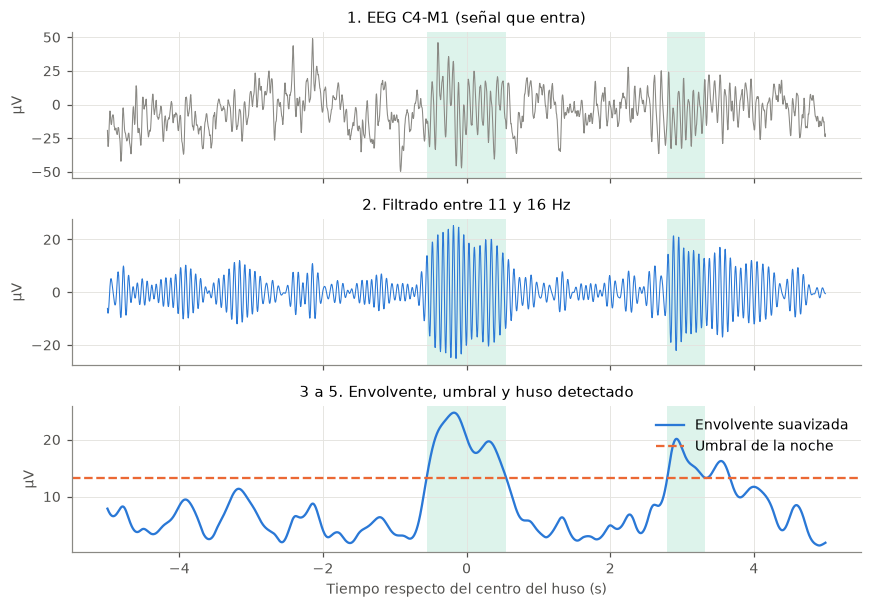

In [4]:
from estadios.comun.constantes import N2
from estadios.descriptores import husos
from scipy import signal

c4 = registro.senales[cfg.canal_husos]
filtrada = signal.sosfiltfilt(signal.butter(4, cfg.husos_banda_hz, "bandpass", fs=fs, output="sos"), c4)
envolvente = husos._envolvente(c4, fs, cfg.husos_banda_hz)
umbral = envolvente.mean() + husos.UMBRAL_DESVIOS * envolvente.std()
tramos = husos.detectar_husos(c4, fs, cfg.husos_banda_hz, cfg.husos_duracion_s)

# Un huso dentro de una época de N2, en el medio de la noche.
n_epoca = int(30 * fs)
en_n2 = [t for t in tramos if estadios_tecnicos[min(int(t.mean()) // n_epoca, registro.n_epocas - 1)] == N2]
inicio, fin = en_n2[len(en_n2) // 2]
centro = (inicio + fin) // 2
ventana = slice(centro - int(5 * fs), centro + int(5 * fs))
t = (np.arange(ventana.start, ventana.stop) - centro) / fs

fig, axs = plt.subplots(3, 1, figsize=(8, 5.6), sharex=True)
axs[0].plot(t, c4[ventana], color=GRIS, lw=0.7)
axs[0].set(title=f"1. {cfg.canal_husos} (señal que entra)", ylabel="µV")
axs[1].plot(t, filtrada[ventana], color=AZUL, lw=0.7)
axs[1].set(title="2. Filtrado entre 11 y 16 Hz", ylabel="µV")
axs[2].plot(t, envolvente[ventana], color=AZUL, label="Envolvente suavizada")
axs[2].axhline(umbral, color=NARANJA, ls="--", label="Umbral de la noche")
axs[2].set(title="3 a 5. Envolvente, umbral y huso detectado", ylabel="µV", xlabel="Tiempo respecto del centro del huso (s)")
axs[2].legend(loc="upper right")
for ax in axs:
    for a, b in tramos:
        if a < ventana.stop and b > ventana.start:
            ax.axvspan((a - centro) / fs, (b - centro) / fs, color=VERDE, alpha=0.15, lw=0)
fig.tight_layout()
guardar(fig, "b_husos_pasos")
print(f"Husos detectados en la noche: {len(tramos)}. Umbral: {umbral:.1f} µV.")

En la señal cruda (arriba) el huso apenas se distingue del resto del EEG. Al filtrar
aparece como una oscilación que crece y decrece, con la forma de huso que le da el
nombre, y la envolvente lo convierte en una loma que cruza el umbral. La franja verde
marca el tramo detectado.

## 2. Cuántos husos hay en cada estadio

`descriptores_husos()` cuenta, para cada época, los husos cuyo centro cae en ella, y
promedia su amplitud (el máximo de la envolvente en cada huso). Una época sin husos
vale 0 en los dos descriptores.

{'husos.cantidad': np.float64(1.13), 'husos.amplitud': np.float64(12.97)}


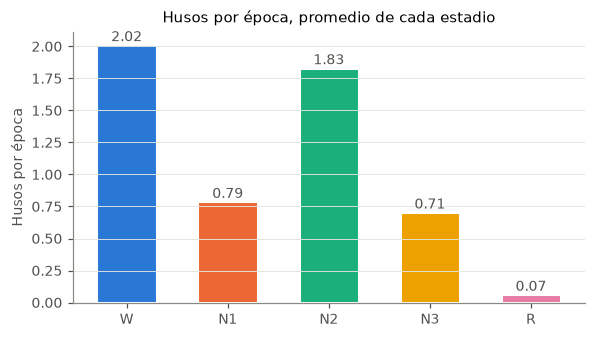

In [5]:
matriz, nombres = husos.descriptores_husos(prep, cfg)
cantidad = matriz[:, nombres.index("husos.cantidad")]

fig, ax = plt.subplots(figsize=(6, 3.2))
medias = [cantidad[estadios_tecnicos == e].mean() if (estadios_tecnicos == e).any() else 0 for e in range(N_ESTADIOS)]
ax.bar(NOMBRES_ESTADIOS, medias, color=[COLOR_ESTADIO[n] for n in NOMBRES_ESTADIOS], width=0.6, edgecolor="white", linewidth=2)
for x, m in enumerate(medias):
    ax.text(x, m, f"{m:.2f}", ha="center", va="bottom", color=TINTA)
ax.set(title="Husos por época, promedio de cada estadio", ylabel="Husos por época")
ax.grid(axis="x", visible=False)
guardar(fig, "b_husos_por_estadio")
print(dict(zip(nombres, matriz.mean(axis=0).round(2))))

REM tiene casi cero husos y N2 tiene casi dos por época, como espera el manual.

**Husos en vigilia (W), con la señal preprocesada.** Se completará cuando se complete A.

## 3. Lo que sale de este capítulo

Dos descriptores por época: `husos.cantidad` y `husos.amplitud`. Los parámetros que el
anteproyecto no fija (el factor 1,5 del umbral y el suavizado de 0,2 s) están como
constantes al principio de `husos.py` y siguen a Mölle et al. (2002).